# 01 Trace EDA (M0.3, Tier A)

Skeleton only. Write the analysis cells yourself. Record findings in ADR-009 in your own words.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from marl_lb.data.traces import load_azure_2023, load_burstgpt

In [ ]:
from pathlib import Path
raw=Path('../data/raw')
traces={
    'azure_conv': load_azure_2023(raw/'AzureLLMInferenceTrace_conv.csv',drop_failures=False),
    'azure_code': load_azure_2023(raw/'AzureLLMInferenceTrace_code.csv',drop_failures=False),
    'burstgpt_1': load_burstgpt(raw/'BurstGPT_1.csv',drop_failures=False),
    'burstgpt_3': load_burstgpt(raw/'BurstGPT_3.csv',drop_failures=False),
}

for name,df in traces.items():
    print(f"{name} rows={len(df):>8,}  failures={df.attrs['n_failures']:>7,}")

traces['azure_conv'].head()


## (a) Row counts and time span
How many rows does each file have, and what time span does each cover?

In [3]:
for name, df in traces.items():
    duration_s = df["arrival_s"].max()
    print(name, "rows:", len(df), "seconds:", round(duration_s), "hours:", round(duration_s / 3600, 2), "days:", round(duration_s / 86400, 2))


azure_conv rows: 19366 seconds: 3502 hours: 0.97 days: 0.04
azure_code rows: 8819 seconds: 3436 hours: 0.95 days: 0.04
burstgpt_1 rows: 1429737 seconds: 5269968 hours: 1463.88 days: 61.0
burstgpt_3 rows: 5344021 seconds: 9503873 hours: 2639.96 days: 110.0


## (b) Arrival rate and burstiness
How does the arrival rate vary over time, and what is the inter-arrival coefficient of variation c_a of each trace?

In [4]:
for name, df in traces.items():
    duration_s = df["arrival_s"].max()
    rate = len(df) / duration_s
    print(name, "mean req/s:", round(rate, 3))


azure_conv mean req/s: 5.53
azure_code mean req/s: 2.567
burstgpt_1 mean req/s: 0.271
burstgpt_3 mean req/s: 0.562


azure_conv min: 37 mean: 328.2 max: 507


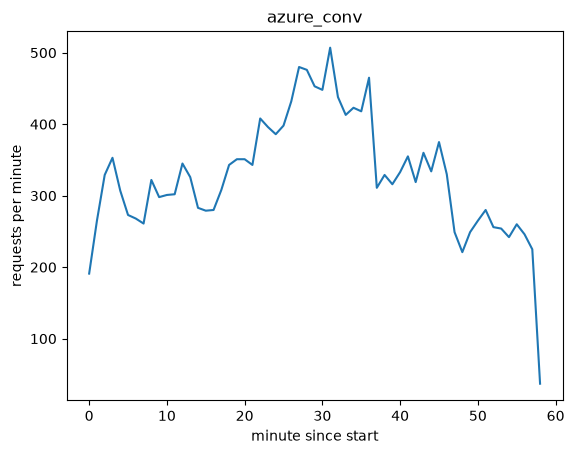

azure_code min: 0 mean: 152.1 max: 632


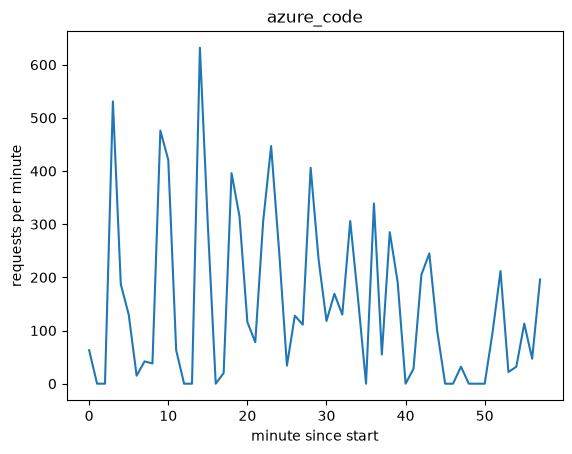

burstgpt_1 min: 0 mean: 16.3 max: 1315


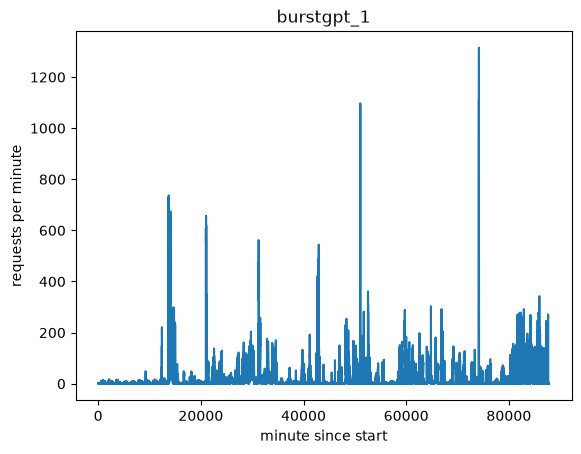

burstgpt_3 min: 0 mean: 33.7 max: 1036


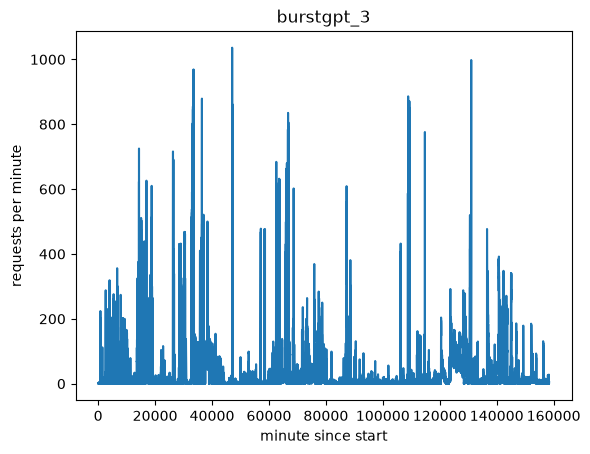

In [5]:
## request per. minute over time

for name , df in traces.items():
    minute=(df['arrival_s']//60).astype(int)
    per_minute=minute.value_counts().sort_index()
    per_minute=per_minute.reindex(range(minute.max()+1),fill_value=0)
    print(name, "min:", per_minute.min(), "mean:", round(per_minute.mean(), 1), "max:", per_minute.max())


    plt.figure()
    plt.plot(per_minute.values)
    plt.title(name)
    plt.xlabel("minute since start")
    plt.ylabel("requests per minute")
    plt.show()

    

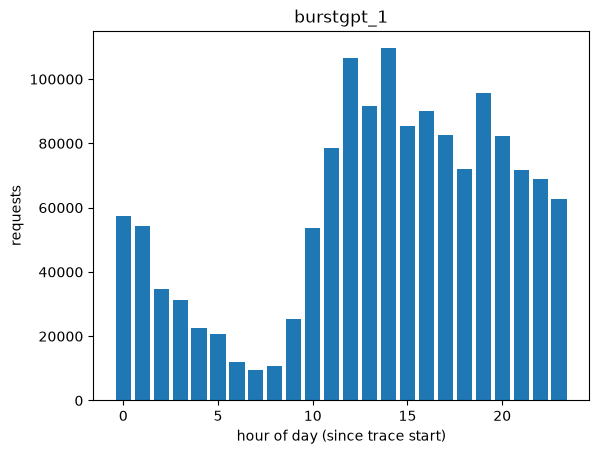

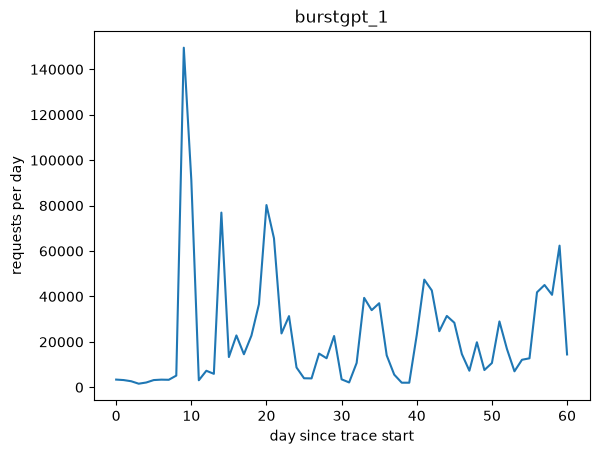

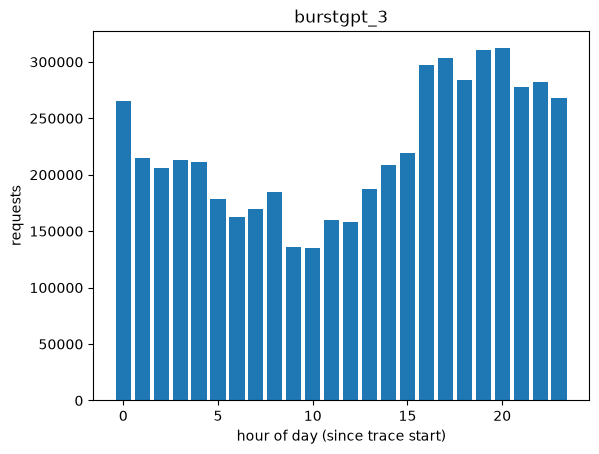

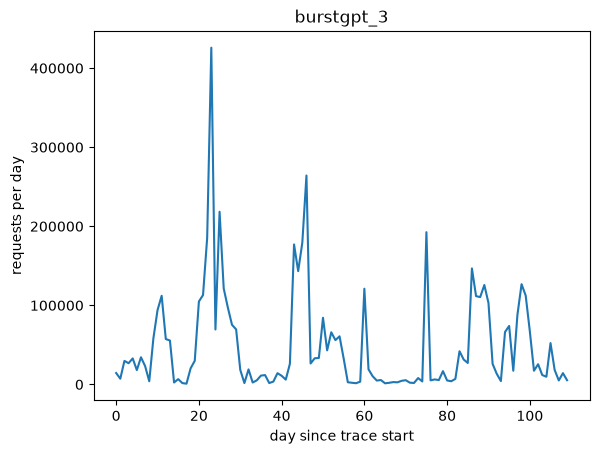

In [6]:
for name in ["burstgpt_1", "burstgpt_3"]:
    df = traces[name]
    hour_of_day = ((df['arrival_s']//3600)%24).astype(int)
    per_hour=hour_of_day.value_counts().sort_index()
    plt.figure()
    plt.bar(per_hour.index, per_hour.values)
    plt.xlabel("hour of day (since trace start)")
    plt.ylabel("requests")
    plt.title(name)
    day = (df["arrival_s"] // 86400).astype(int)
    per_day = day.value_counts().sort_index()
    per_day = per_day.reindex(range(day.max() + 1), fill_value=0)
    plt.figure()
    plt.plot(per_day.values)
    plt.xlabel("day since trace start")
    plt.ylabel("requests per day")
    plt.title(name)
    plt.show()





In [7]:
for name,df in traces.items():
    gaps=df['arrival_s'].diff().dropna()
    zero=(gaps==0).sum()
    print(name, "gaps:", len(gaps), "zero gaps:", zero, "share zero:", round(zero / len(gaps), 4))
    print("   smallest non-zero gap:", gaps[gaps > 0].min())
    print("   mean gap:", round(gaps.mean(), 3), "median gap:", round(gaps.median(), 3),'mean_rate:',round(1/gaps.mean(),3))
    print("   largest gap:", gaps.max(), "seconds, ending at row", gaps.idxmax())
    print('\n')
# azure_conv mean req/s: 5.53
# azure_code mean req/s: 2.567
# burstgpt_1 mean req/s: 0.271
# burstgpt_3 mean req/s: 0.562



azure_conv gaps: 19365 zero gaps: 0 share zero: 0.0
   smallest non-zero gap: 1.9999999949504854e-06
   mean gap: 0.181 median gap: 0.118 mean_rate: 5.53
   largest gap: 4.314579 seconds, ending at row 1


azure_code gaps: 8818 zero gaps: 0 share zero: 0.0
   smallest non-zero gap: 5.999999757477781e-06
   mean gap: 0.39 median gap: 0.064 mean_rate: 2.566
   largest gap: 217.168952 seconds, ending at row 8100


burstgpt_1 gaps: 1429736 zero gaps: 652442 share zero: 0.4563
   smallest non-zero gap: 1.0
   mean gap: 3.686 median gap: 1.0 mean_rate: 0.271
   largest gap: 15240.0 seconds, ending at row 1176664


burstgpt_3 gaps: 5344020 zero gaps: 3651379 share zero: 0.6833
   smallest non-zero gap: 1.0
   mean gap: 1.778 median gap: 0.0 mean_rate: 0.562
   largest gap: 18872.0 seconds, ending at row 2182742




In [8]:
df1 = traces["burstgpt_1"]
print(df1.loc[1176664 - 2 : 1176664 + 2, ["arrival_s", "prompt_tokens", "output_tokens"]])

df3 = traces["burstgpt_3"]
print(df3.loc[2182742 - 2 : 2182742 + 2, ["arrival_s", "prompt_tokens", "output_tokens"]])


         arrival_s  prompt_tokens  output_tokens
1176662  4507624.0           1425            152
1176663  4507654.0           1152            247
1176664  4522894.0             19            303
1176665  4522924.0            344            367
1176666  4522962.0            732             94
         arrival_s  prompt_tokens  output_tokens
2182740  3294158.0             40              5
2182741  3294165.0             36              3
2182742  3313037.0            340            738
2182743  3313051.0            488            657
2182744  3313143.0            340            743


In [9]:
# c_a = std of the gaps / mean of the gaps (coefficient of variation of inter-arrival times).
# c_a = 1 is Poisson (random, independent) traffic; c_a > 1 is burstier than random.
# BurstGPT only records whole seconds, so many gaps are exactly 0 (ties). To fix that we add a
# random number in [0, 1) to every timestamp (spreads tied requests inside their second).
# ASSUMPTION: arrivals are evenly spread inside each second.
rng = np.random.default_rng(0)  # fixed seed -> same result every run
ca_by_trace = {}  # saved here so the summary cell at the end can reuse it

for name, df in traces.items():
    t = df["arrival_s"].values
    gaps = np.diff(t)                      # gap between each request and the one before it
    ca_raw = gaps.std() / gaps.mean()      # c_a on the raw timestamps

    if (gaps == 0).any():                  # only traces with ties (BurstGPT) get the fix
        t = np.sort(t + rng.random(len(t)))  # jitter, then sort to restore time order
        gaps = np.diff(t)                  # recompute the gaps from the jittered times
    ca_fixed = gaps.std() / gaps.mean()    # c_a after the tie fix (same as raw when no ties)

    ca_by_trace[name] = ca_fixed
    print(name, "c_a raw:", round(ca_raw, 4), "c_a after tie fix:", round(ca_fixed, 4))


azure_conv c_a raw: 1.0942 c_a after tie fix: 1.0942
azure_code c_a raw: 13.1513 c_a after tie fix: 13.1513
burstgpt_1 c_a raw: 13.2821 c_a after tie fix: 13.2818
burstgpt_3 c_a raw: 17.7496 c_a after tie fix: 17.7476


In [10]:
for name, df in traces.items():
    t = df["arrival_s"].values
    gaps = np.diff(t)
    if (gaps == 0).any():
        t2 = np.sort(t + rng.random(len(t)))
        gaps2 = np.diff(t2)
        print(name, "zero gaps before:", (gaps == 0).sum(), "after:", (gaps2 == 0).sum())
        print("   std before:", gaps.std(), "std after:", gaps2.std())


burstgpt_1 zero gaps before: 652442 after: 0
   std before: 48.95729991259393 std after: 48.95614807416745
burstgpt_3 zero gaps before: 3651379 after: 0
   std before: 31.56614261068613 std after: 31.56295062449067


In [11]:
# Index of dispersion of counts (IDC) = variance of "requests per window" / mean of it.
# Poisson (random, independent) traffic gives IDC = 1; bursty traffic gives IDC > 1.
# Counting per window does not depend on the order of requests inside a window, so the
# whole-second ties in BurstGPT cannot distort it (unlike the gaps).
idc = {}  # idc[trace name][window length in seconds], reused by the summary cell

for name, df in traces.items():
    t = df["arrival_s"].values
    windows = [1, 10, 60]
    if name.startswith("burstgpt"):
        windows.append(3600)  # Azure lasts ~1 h, so a 1 h window would leave a single count
    idc[name] = {}
    for w in windows:
        counts = np.bincount((t // w).astype(int))  # requests in each window (empty windows = 0)
        counts = counts[:-1]                        # drop the last window: only partly covered
        idc[name][w] = counts.var() / counts.mean()
        print(name, "window", w, "s  IDC:", round(idc[name][w], 2))


azure_conv window 1 s  IDC: 1.39
azure_conv window 10 s  IDC: 3.86
azure_conv window 60 s  IDC: 16.13
azure_code window 1 s  IDC: 13.19
azure_code window 10 s  IDC: 71.64
azure_code window 60 s  IDC: 163.96
burstgpt_1 window 1 s  IDC: 3.84
burstgpt_1 window 10 s  IDC: 24.76
burstgpt_1 window 60 s  IDC: 138.19
burstgpt_1 window 3600 s  IDC: 5321.02
burstgpt_3 window 1 s  IDC: 8.28
burstgpt_3 window 10 s  IDC: 44.35
burstgpt_3 window 60 s  IDC: 229.67
burstgpt_3 window 3600 s  IDC: 10605.66


### Why c_a and the dispersion depend on the window and on non-stationarity (Guide B5, Kingman)
- **c_a** looks at gaps between neighbouring requests. **IDC** (index of dispersion of counts) = variance / mean of the number of requests per window of length w. Poisson traffic gives 1 for both, at every w.
- If the *rate itself changes* (daily cycle, slow trend, hours-long lulls), then windows from busy periods and windows from quiet periods have very different counts. That adds to the variance, so IDC grows with w and c_a gets inflated by the long gaps. This is **non-stationarity**, and it is not the same thing as short-term burstiness.
- **Kingman**: for one server, mean queueing wait ≈ ρ/(1−ρ) × (c_a² + c_s²)/2 × E[S] (ρ = utilisation, c_s = coefficient of variation of service time, E[S] = mean service time). Waiting grows with c_a², but it is the burstiness at the time scale of queueing (seconds to minutes) that matters, so short-window IDC is the relevant number, not a whole-trace c_a.
- The cell below compares the IDC over the whole trace with the IDC inside short slices where the rate is roughly steady.


In [12]:
# Does the dispersion come from short-term bursts, or from the rate changing over hours/days?
# We cut each trace into slices (inside one slice the rate is roughly steady), compute the IDC
# of 10 s counts inside each slice, and compare with the IDC over the whole trace.
# whole trace >> typical slice  ->  most of the dispersion is non-stationarity (cycle / trend).
w = 10  # window length in seconds

for name, df in traces.items():
    t = df["arrival_s"].values
    slice_len = 600 if name.startswith("azure") else 3600   # Azure lasts ~1 h, so use 10 min slices
    per_slice = slice_len // w                               # number of 10 s windows in one slice

    counts = np.bincount((t // w).astype(int))              # requests per 10 s window
    n_slices = len(counts) // per_slice                      # keep whole slices only
    counts = counts[: n_slices * per_slice].reshape(n_slices, per_slice)  # one row per slice

    mean = counts.mean(axis=1)                               # mean count per window, per slice
    var = counts.var(axis=1)                                 # variance of counts, per slice
    ok = mean > 0                                            # skip empty slices (would divide by 0)
    idc_slice = var[ok] / mean[ok]                           # IDC inside each slice

    whole = counts.var() / counts.mean()                     # IDC over all windows of the trace
    rate = mean[ok] / w                                      # mean req/s of each slice
    print(name, "| IDC whole trace:", round(whole, 2),
          "| IDC per slice, median:", round(np.median(idc_slice), 2),
          "| slices:", int(ok.sum()))
    print("   slice rate req/s  p10:", round(np.percentile(rate, 10), 3),
          " p90:", round(np.percentile(rate, 90), 3))


azure_conv | IDC whole trace: 3.41 | IDC per slice, median: 2.12 | slices: 5
   slice rate req/s  p10: 4.946  p90: 6.835
azure_code | IDC whole trace: 72.61 | IDC per slice, median: 67.57 | slices: 5
   slice rate req/s  p10: 1.597  p90: 3.554
burstgpt_1 | IDC whole trace: 24.76 | IDC per slice, median: 1.06 | slices: 1427
   slice rate req/s  p10: 0.002  p90: 0.767
burstgpt_3 | IDC whole trace: 44.35 | IDC per slice, median: 1.06 | slices: 2585
   slice rate req/s  p10: 0.004  p90: 1.583


## (c) P and O distributions
What do the prompt-token (P) and output-token (O) distributions look like on a log scale, and what are p50, p95 and p99 of each?

In [13]:
# Percentiles of prompt tokens (P) and output tokens (O) for every trace.
# p50 = the middle request, p99 = only 1% of requests are bigger. max = the single biggest.
# M0.4 will use the p99 of each feature as its normalisation constant (value / p99, clipped to 1).
# NOTE: failure rows (O = 0) are still included here, so they pull the O percentiles down a bit.
rows = []
for name, df in traces.items():
    for col in ["prompt_tokens", "output_tokens"]:
        q = df[col].quantile([0.5, 0.9, 0.95, 0.99])  # linear interpolation between ranks
        rows.append({"trace": name, "column": col,
                     "p50": q[0.5], "p90": q[0.9], "p95": q[0.95], "p99": q[0.99],
                     "max": df[col].max()})
pct_table = pd.DataFrame(rows)
print(pct_table.to_string(index=False))


     trace        column    p50    p90    p95     p99    max
azure_conv prompt_tokens 1020.0 2734.5 4083.0 4142.00  14050
azure_conv output_tokens  129.0  424.0  451.0  601.00   1000
azure_code prompt_tokens 1469.0 5187.6 7303.3 7436.00   7437
azure_code output_tokens   13.0   55.0   90.0  251.46   1899
burstgpt_1 prompt_tokens  251.0 1796.0 2461.0 3387.00  29665
burstgpt_1 output_tokens   34.0  272.0  460.0 1491.00   7315
burstgpt_3 prompt_tokens  327.0  836.0 1405.0 3354.00 125591
burstgpt_3 output_tokens   14.0  129.0  324.0  876.00   5383


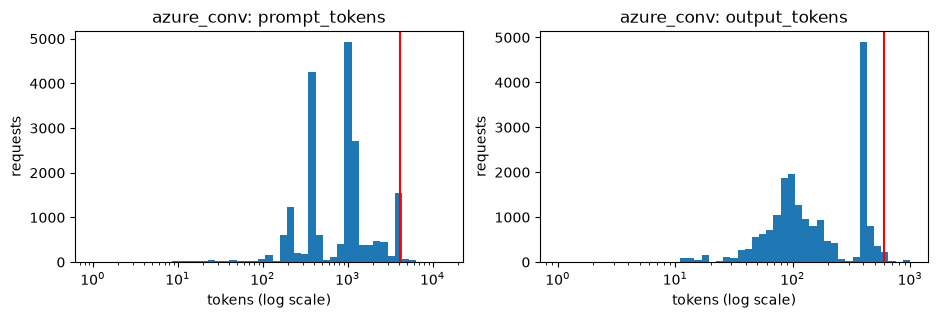

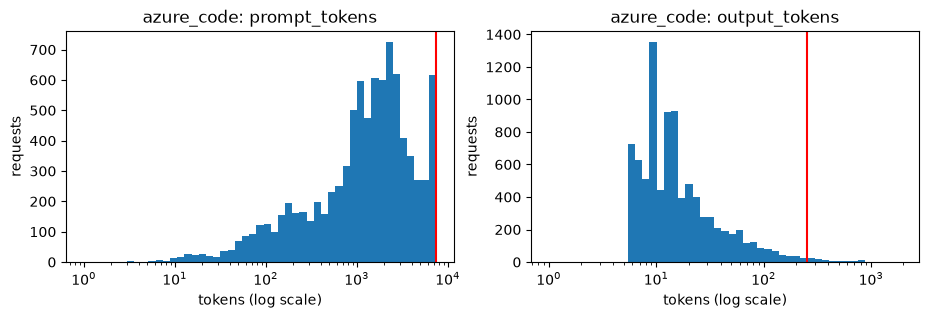

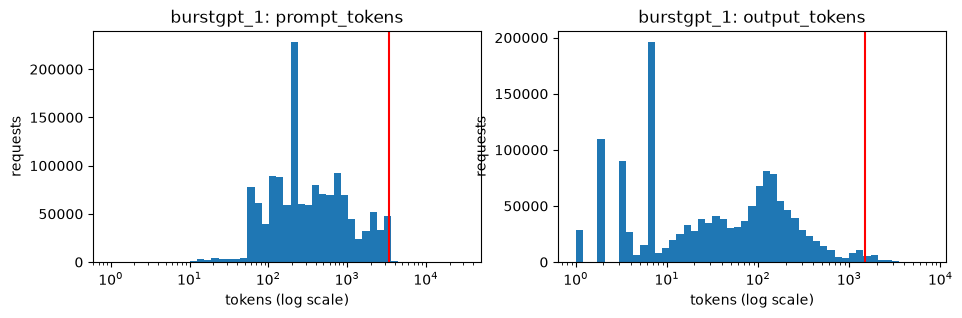

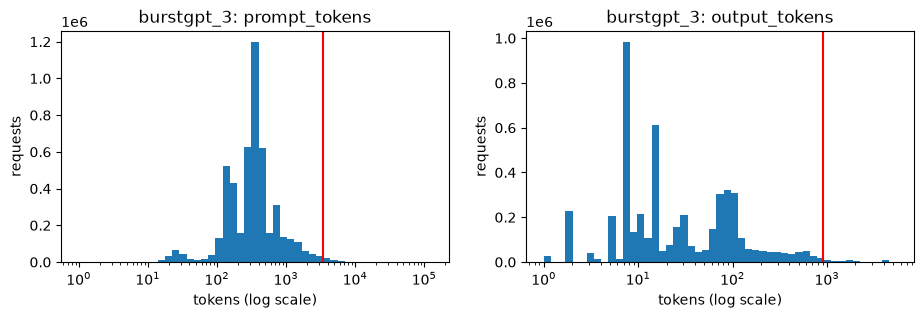

In [14]:
# Histograms of P and O on a log x-axis (heavy tail: many small requests, a few huge ones).
# Equal-width bins on a log axis = bins that are equal in ratio (1-2, 2-4, 4-8 ...),
# so both the small and the huge requests are visible. The red line is the p99.
for name, df in traces.items():
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    for ax, col in zip(axes, ["prompt_tokens", "output_tokens"]):
        values = df[col][df[col] > 0]                         # a log axis cannot show 0 (failure rows)
        bins = np.logspace(0, np.log10(values.max()), 50)     # 50 log-spaced bins from 1 token up
        ax.hist(values, bins=bins)
        ax.axvline(values.quantile(0.99), color="red")        # p99 (this is the M0.4 constant)
        ax.set_xscale("log")
        ax.set_xlabel("tokens (log scale)")
        ax.set_ylabel("requests")
        ax.set_title(f"{name}: {col}")
    plt.show()


## (d) P-O relationship
Are P and O related, and how strongly?

In [15]:
# Spearman correlation between P and O.
# Spearman correlates the RANKS (1st smallest, 2nd smallest, ...) instead of the raw values,
# so a few huge requests cannot dominate it (the token counts are heavy-tailed).
# +1 = bigger prompts always mean bigger outputs, 0 = no relation, -1 = the opposite.
# Computed twice: on all rows, and without failure rows (O = 0), which would distort the ranks.
for name, df in traces.items():
    all_rows = df["prompt_tokens"].corr(df["output_tokens"], method="spearman")
    ok = df["output_tokens"] > 0
    no_fail = df.loc[ok, "prompt_tokens"].corr(df.loc[ok, "output_tokens"], method="spearman")
    print(name, "Spearman P-O, all rows:", round(all_rows, 3), "| without failure rows:", round(no_fail, 3))


azure_conv Spearman P-O, all rows: 0.073 | without failure rows: 0.073
azure_code Spearman P-O, all rows: -0.021 | without failure rows: -0.021
burstgpt_1 Spearman P-O, all rows: 0.429 | without failure rows: 0.398
burstgpt_3 Spearman P-O, all rows: 0.213 | without failure rows: 0.012


## (k) BurstGPT failure rows (ADR-017)
How many rows have `output_tokens == 0`, do they carry prompt tokens (prefill load), and when and in which Model / Log Type do they occur? Findings go into ADR-017.


In [16]:
# Failure rows = rows with output_tokens == 0 (ADR-017).
# Question: do they still carry prompt tokens? If yes, the server did the prefill work
# for them, so dropping them would understate the load.
for name, df in traces.items():
    fail = df["output_tokens"] == 0
    print(name, "failure rows:", int(fail.sum()), "share:", round(fail.mean(), 4))
    if fail.any():
        p_fail = df.loc[fail, "prompt_tokens"]    # prompt tokens of the failure rows
        p_ok = df.loc[~fail, "prompt_tokens"]     # prompt tokens of all the other rows
        print("   P of failure rows, p50/p90/p99:", p_fail.quantile([0.5, 0.9, 0.99]).tolist())
        print("   P of other rows,   p50/p90/p99:", p_ok.quantile([0.5, 0.9, 0.99]).tolist())
        print("   failure rows with P == 0:", round((p_fail == 0).mean(), 4))
        # share of ALL prompt tokens that sit in failure rows = prefill load that dropping would hide
        print("   share of all prompt tokens in failure rows:",
              round(p_fail.sum() / df["prompt_tokens"].sum(), 4))


azure_conv failure rows: 0 share: 0.0
azure_code failure rows: 0 share: 0.0
burstgpt_1 failure rows: 25443 share: 0.0178
   P of failure rows, p50/p90/p99: [0.0, 0.0, 0.0]
   P of other rows,   p50/p90/p99: [262.0, 1824.0, 3389.0]
   failure rows with P == 0: 0.9994
   share of all prompt tokens in failure rows: 0.0
burstgpt_3 failure rows: 387963 share: 0.0726
   P of failure rows, p50/p90/p99: [0.0, 0.0, 0.0]
   P of other rows,   p50/p90/p99: [340.0, 884.0, 3482.0]
   failure rows with P == 0: 1.0
   share of all prompt tokens in failure rows: 0.0


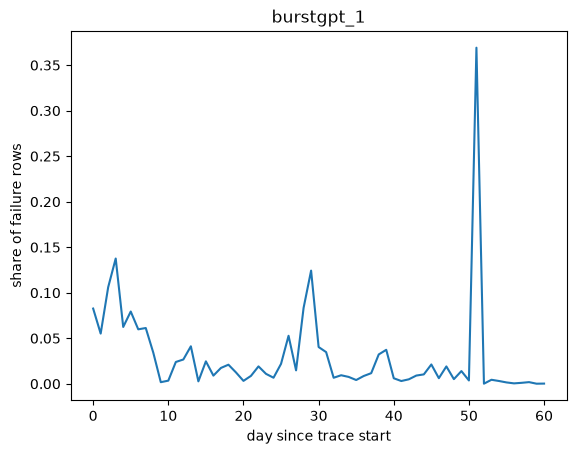

burstgpt_1 - failures by Model
         failures     rows     share
Model                               
ChatGPT     20942  1210109  0.017306
GPT-4        4501   219628  0.020494
burstgpt_1 - failures by Log Type
                  failures     rows     share
Log Type                                     
API log              16931  1275518  0.013274
Conversation log      8512   154219  0.055194


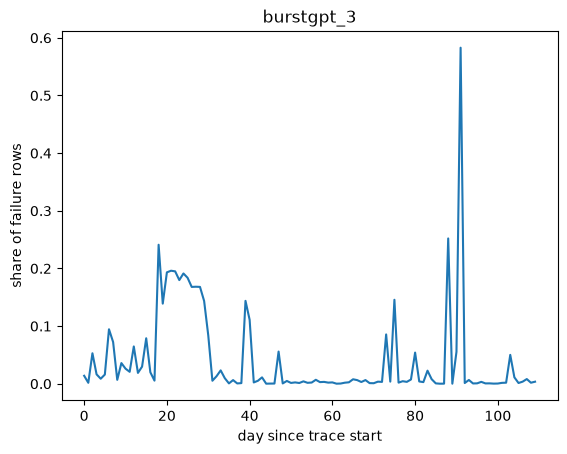

burstgpt_3 - failures by Model
         failures     rows     share
Model                               
ChatGPT    352260  4553782  0.077355
GPT-4       35703   790239  0.045180
burstgpt_3 - failures by Log Type
                  failures     rows     share
Log Type                                     
API log             386107  5110404  0.075553
Conversation log      1856   233617  0.007945


In [17]:
# When do failures happen, and which Model / Log Type do they belong to?
# 1) share of failure rows per day (BurstGPT only: the Azure traces have no failures)
# 2) failure share per Model and per Log Type, where those columns exist
for name in ["burstgpt_1", "burstgpt_3"]:
    df = traces[name]
    fail = df["output_tokens"] == 0                       # True for failure rows
    day = (df["arrival_s"] // 86400).astype(int)          # day number since the trace start
    share_per_day = fail.groupby(day).mean()              # mean of True/False = share of failures
    plt.figure()
    plt.plot(share_per_day.index, share_per_day.values)
    plt.xlabel("day since trace start")
    plt.ylabel("share of failure rows")
    plt.title(name)
    plt.show()

    for col in ["Model", "Log Type"]:
        if col in df.columns:                             # skip columns this file does not have
            by = fail.groupby(df[col], observed=True).agg(["sum", "count", "mean"])
            print(name, "- failures by", col)
            print(by.rename(columns={"sum": "failures", "count": "rows", "mean": "share"}))


## (e) BurstGPT Session ID coverage
What fraction of BurstGPT rows (and of conversation-mode rows) carry a usable Session ID?

In [18]:
# How many BurstGPT_3 rows carry a Session ID? (BurstGPT_1 has no Session ID column at all.)
# Rows without one are API-mode or not session-tracked, so they cannot use a session-based cache.
b3 = traces["burstgpt_3"]
has_sid = b3["session_id"].notna()    # True when the row has a Session ID
print("rows with a Session ID:", int(has_sid.sum()), "of", len(b3), "share:", round(has_sid.mean(), 4))

# Which Log Type are the rows (conversation-mode vs API-mode)? Session IDs probably sit in one of them.
print(b3["Log Type"].value_counts())
print(has_sid.groupby(b3["Log Type"], observed=True).agg(["sum", "count", "mean"]))


rows with a Session ID: 233617 of 5344021 share: 0.0437
Log Type
API log             5110404
Conversation log     233617
Name: count, dtype: int64
                     sum    count  mean
Log Type                               
API log                0  5110404   0.0
Conversation log  233617   233617   1.0


## (f) Token growth within a session
Within a session, do Request tokens grow from turn to turn? Is the conversation history included in the prompt?

In [19]:
# History-inclusion test. If the chat history is re-sent with every turn, then at turn t
#   prompt_tokens[t]  ~  prompt_tokens[t-1] + output_tokens[t-1] + (new user text)
# so  diff = prompt[t] - (prompt[t-1] + output[t-1])  should be >= 0 and smallish.
# If history is NOT included, prompts stay about the same size and diff is mostly negative.
b3 = traces["burstgpt_3"]
has_sid = b3["session_id"].notna()
s = b3.loc[has_sid, ["session_id", "arrival_s", "prompt_tokens", "output_tokens"]]
s = s.sort_values(["session_id", "arrival_s"], kind="stable")   # turns of a session in time order

g = s.groupby("session_id")
prev_p = g["prompt_tokens"].shift(1)    # previous turn's prompt tokens (NaN on a session's first turn)
prev_o = g["output_tokens"].shift(1)    # previous turn's output tokens
has_prev = prev_p.notna()               # only turns that have a previous turn can be tested

diff = (s["prompt_tokens"] - (prev_p + prev_o))[has_prev]
print("turns tested:", int(has_prev.sum()))
print("prompt grew vs previous turn:", round((s["prompt_tokens"][has_prev] > prev_p[has_prev]).mean(), 4))
print("prompt >= previous prompt + previous output:", round((diff >= 0).mean(), 4))
print("diff quantiles p10/p50/p90:", diff.quantile([0.1, 0.5, 0.9]).tolist())
history_share = (diff >= 0).mean()      # reused by the summary cell


turns tested: 177697
prompt grew vs previous turn: 0.7779
prompt >= previous prompt + previous output: 0.5867
diff quantiles p10/p50/p90: [-457.0, 15.0, 119.0]


## (g) Session length distribution
How many turns does a session have, and what is the distribution?

In [20]:
# Session length: how many turns per session, how far apart are the turns, how long does a
# session last. The turn gaps and session durations also tell us how wide an embargo gap
# between train and held-out would have to be (ADR-016) and what a prefix cache must keep alive.
b3 = traces["burstgpt_3"]
has_sid = b3["session_id"].notna()
s = b3.loc[has_sid, ["session_id", "arrival_s"]].sort_values(["session_id", "arrival_s"], kind="stable")

turns = s.groupby("session_id").size()                  # number of turns of each session
print("sessions:", len(turns), "| single-turn sessions:", round((turns == 1).mean(), 4))
print("turns per session p50/p90/p99/max:", turns.quantile([0.5, 0.9, 0.99]).tolist(), turns.max())
print(turns.value_counts().sort_index().head(10))       # how many sessions have 1, 2, 3 ... turns

turn_gaps = s.groupby("session_id")["arrival_s"].diff().dropna()   # seconds between consecutive turns
print("gap between turns (s) p50/p90/p99/max:", turn_gaps.quantile([0.5, 0.9, 0.99]).tolist(), turn_gaps.max())

span = s.groupby("session_id")["arrival_s"].agg(["min", "max"])
duration = span["max"] - span["min"]                    # first turn to last turn, in seconds
print("session duration (s) p50/p90/p99/max:", duration.quantile([0.5, 0.9, 0.99]).tolist(), duration.max())


sessions: 55920 | single-turn sessions: 0.3547
turns per session p50/p90/p99/max: [2.0, 9.0, 31.0] 436
1     19834
2     11389
3      6665
4      4268
5      2874
6      2072
7      1577
8      1152
9       989
10      721
Name: count, dtype: int64
gap between turns (s) p50/p90/p99/max: [131.0, 2340.0, 78787.80000000098] 4825463.0
session duration (s) p50/p90/p99/max: [121.0, 11812.499999999993, 312894.24999999296] 7864148.0


## (h) Azure columns
Does Azure 2023 have only TIMESTAMP, ContextTokens and GeneratedTokens? Confirm, and note what that means for conversation ids.

In [21]:
raw_conv=pd.read_csv('../data/raw/AzureLLMInferenceTrace_conv.csv',nrows=0)
raw_code=pd.read_csv('../data/raw/AzureLLMInferenceTrace_code.csv',nrows=0)
print(list(raw_conv.columns))
print(list(raw_code.columns))

['TIMESTAMP', 'ContextTokens', 'GeneratedTokens']
['TIMESTAMP', 'ContextTokens', 'GeneratedTokens']


## (i) Held-out size after a time split
After a time-ordered train/held-out split, is the held-out part large enough? Give the request count of each part, per trace.

In [22]:
# Time-ordered split at 80% of each trace's DURATION (first 80% of the time = train,
# last 20% = held-out). Nothing is shuffled. Prints the size of both parts and their mean rates,
# so you can see whether the held-out part is big enough and whether its load differs.
for name, df in traces.items():
    t = df["arrival_s"].values
    cut = 0.8 * t.max()                       # time (s) where train ends and held-out starts
    n_train = int((t < cut).sum())            # requests before the cut
    n_held = int((t >= cut).sum())            # requests after the cut
    held_s = t.max() - cut                    # length of the held-out part in seconds
    print(name, "| train:", n_train, "| held-out:", n_held,
          "| held-out length (min):", round(held_s / 60, 1),
          "| train req/s:", round(n_train / cut, 3),
          "| held-out req/s:", round(n_held / held_s, 3))


azure_conv | train: 16495 | held-out: 2871 | held-out length (min): 11.7 | train req/s: 5.888 | held-out req/s: 4.099
azure_code | train: 8068 | held-out: 751 | held-out length (min): 11.5 | train req/s: 2.935 | held-out req/s: 1.093
burstgpt_1 | train: 1120335 | held-out: 309402 | held-out length (min): 17566.6 | train req/s: 0.266 | held-out req/s: 0.294
burstgpt_3 | train: 4249532 | held-out: 1094489 | held-out length (min): 31679.6 | train req/s: 0.559 | held-out req/s: 0.576


## (j) Findings for ADR-009
Which findings from (a)-(i) change a design decision? Write them into ADR-009 in your own words.

In [23]:
# Summary: one JSON file with the per-trace numbers, written to results/eda/trace_summary.json.
# Needs the variables from the cells above: ca_by_trace (c_a), idc (dispersion), pct_table is
# not needed (percentiles are recomputed here), turns / turn_gaps / history_share (sessions).
# Nothing is written to data/raw.
import json

summary = {}
for name, df in traces.items():
    fail = df["output_tokens"] == 0
    duration_s = df["arrival_s"].max()
    entry = {
        "rows": len(df),
        "duration_s": duration_s,
        "mean_rate_rps": len(df) / duration_s,
        "c_a": ca_by_trace[name],                 # after the tie fix (same as raw for Azure)
        "idc_by_window_s": idc[name],             # {window length in s: IDC}
        "failure_rows": int(fail.sum()),
        "failure_share": fail.mean(),
    }
    for col in ["prompt_tokens", "output_tokens"]:
        q = df[col].quantile([0.5, 0.9, 0.95, 0.99])
        entry[col] = {"p50": q[0.5], "p90": q[0.9], "p95": q[0.95], "p99": q[0.99], "max": df[col].max()}
    summary[name] = entry

# Session statistics exist only for BurstGPT_3 (the other three have no Session ID).
b3 = traces["burstgpt_3"]
has_sid = b3["session_id"].notna()
summary["burstgpt_3"]["sessions"] = {
    "rows_with_session_id": int(has_sid.sum()),
    "share_rows_with_session_id": has_sid.mean(),
    "n_sessions": len(turns),
    "turns_p50": turns.quantile(0.5),
    "turns_p90": turns.quantile(0.9),
    "turns_max": turns.max(),
    "turn_gap_s_p50": turn_gaps.quantile(0.5),
    "turn_gap_s_p90": turn_gaps.quantile(0.9),
    "share_turns_prompt_ge_prev_prompt_plus_output": history_share,
}

out_dir = Path("../results/eda")
out_dir.mkdir(parents=True, exist_ok=True)        # creates results/eda if it does not exist
with open(out_dir / "trace_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=lambda o: o.item())   # .item(): numpy number -> python number
print("written:", out_dir / "trace_summary.json")


written: ../results/eda/trace_summary.json


## Bets
Score your M0.1 bets in docs/viva.md against what you found above.